# CSE 4836 - Pattern Recognition Lab 1

# Introduction

In this lab, you will build your own classification library and work through several foundational pattern recognition models in a step-by-step way. You will begin with a K-nearest neighbors classifier, move to a linear classifier trained with gradient descent, build a small automatic differentiation system for tensors, and then use that tensor system to train both a linear classifier and a neural network.

The notebook is organized so that each section first introduces the required code and then asks you to apply or extend it. Your job is to understand how the provided components work, complete the missing parts in the task cells, run experiments on the provided datasets, and explain what the results say about model behavior and decision boundaries.

# Download Files

In [1]:
import os

In [2]:
path = "/content/datasets"

In [3]:
if not os.path.exists(path):
    !gdown 1J9bpSPxMHvsCQNDoa232KVxO2T_1ERIE

In [4]:
if not os.path.exists(path):
    !unzip lab1.zip

# Import External Libraries

In [5]:
import csv
import matplotlib.pyplot as plt
import numpy as np

In [6]:
EPS = 1e-8

# Generic Classes

## `Dataset`
`Dataset` stores pairs of features and class ids and exposes standard Python container behavior so samples can be indexed, counted, and iterated over.

## `Model`
`Model` is the abstract base class for all predictive models in this notebook. Each subclass implements `evaluate` so that it returns a NumPy array containing one score for each class. The class also uses `__call__` so model instances can be used like functions.

In [7]:
class Dataset:
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

    def __iter__(self):
        for x, y in self.data:
            yield x, y

In [8]:
class Model:
    def __init__(self, n_classes):
        self.n_classes = n_classes

    def evaluate(self, x):
        raise NotImplementedError(f"{self.__class__.__name__}.evaluate() must be implemented")

    def __call__(self, x):
        return self.evaluate(x)

# Analyzer Classes

## `ModelPerformanceAnalyzer`
`ModelPerformanceAnalyzer` evaluates a model on a dataset by collecting predictions and then delegating metric computation to a subclass.

## `AccuracyAnalyzer`
`AccuracyAnalyzer` computes the fraction of correctly classified samples.

## `F1Analyzer`
`F1Analyzer` computes the average F1 score over a selected set of class IDs.

In [9]:
class ModelPerformanceAnalyzer:
    def test(self, model, testset):
        y_true = []
        y_pred = []

        for x, y in testset:
            scores = model(x)
            y_hat = np.argmax(scores)

            y_true.append(y)
            y_pred.append(y_hat)

        return self.compute(np.array(y_true), np.array(y_pred))

    def compute(self, y_true, y_pred):
        raise NotImplementedError(f"{self.__class__.__name__}.compute() must be implemented")

In [10]:
class AccuracyAnalyzer(ModelPerformanceAnalyzer):
    def compute(self, y_true, y_pred):
        return np.mean(y_true == y_pred)

In [11]:
class F1Analyzer(ModelPerformanceAnalyzer):
    def __init__(self, n_classes, positive_class_ids=None):
        self.n_classes = n_classes
        self.positive_class_ids = (
            list(range(n_classes)) if positive_class_ids is None else positive_class_ids
        )

    def compute(self, y_true, y_pred):
        f1_scores = []

        for class_id in self.positive_class_ids:
            tp = np.sum((y_pred == class_id) & (y_true == class_id))
            fp = np.sum((y_pred == class_id) & (y_true != class_id))
            fn = np.sum((y_pred != class_id) & (y_true == class_id))

            precision = tp / (tp + fp + EPS)
            recall = tp / (tp + fn + EPS)
            f1 = 2 * precision * recall / (precision + recall + EPS)

            f1_scores.append(f1)

        return np.mean(f1_scores)

# Visualizer Classes

## `DatasetVisualizer2D`
`DatasetVisualizer2D` plots two-dimensional datasets by showing each sample as a point colored by class id.

## `ModelVisualizer2D`
`ModelVisualizer2D` plots the decision regions of a model over a two-dimensional grid and overlays the dataset points on top of that grid.

In [12]:
class DatasetVisualizer2D:
    def __init__(self, cmap="Set1"):
        self.cmap = cmap

    def plot(self, ax, dataset):
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")

        X = np.array([x for x, _ in dataset])
        y = np.array([y for _, y in dataset])

        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=self.cmap)

        return ax

In [13]:
class ModelVisualizer2D:
    def __init__(self, resolution=200, cmap="Set1", alpha=0.3):
        self.resolution = resolution
        self.cmap = cmap
        self.alpha = alpha

    def plot(self, ax, dataset, model):
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")

        X = np.array([x for x, _ in dataset])
        y = np.array([y for _, y in dataset])

        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=self.cmap)

        x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

        xx, yy = np.meshgrid(
            np.linspace(x1_min, x1_max, self.resolution),
            np.linspace(x2_min, x2_max, self.resolution),
        )

        grid = np.c_[xx.ravel(), yy.ravel()]
        scores = np.array([model(x) for x in grid])
        Z = np.argmax(scores, axis=1).reshape(xx.shape)

        ax.contourf(xx, yy, Z, alpha=self.alpha, cmap=self.cmap)

        return ax

In [14]:
data_visualizer = DatasetVisualizer2D()
model_visualizer = ModelVisualizer2D()

# Dataset Classes

## `CsvDataset`
`CsvDataset` loads a dataset from a CSV file where the final column contains the integer class id and all previous columns contain numeric features.

In [15]:
class CsvDataset(Dataset):
    def __init__(self, csv_file_path):
        data = []

        with open(csv_file_path, "r") as f:
            reader = csv.reader(f)
            next(reader)

            for row in reader:
                *features, class_id = row

                x = np.array(features, dtype=float)
                y = int(class_id)

                data.append((x, y))

        super().__init__(data)

# K-Nearest Neighbor Model

## `KnnModel`
`KnnModel` is a subclass of `Model` that stores a training dataset and evaluates class scores for a new sample by finding the nearest neighbors under a chosen distance function and then applying a chosen voting function.

In [16]:
class KnnModel(Model):
    def __init__(self, n_classes, k, distance_fn, voting_fn):
        if distance_fn is None:
            raise ValueError("KnnModel requires a distance_fn")
        if voting_fn is None:
            raise ValueError("KnnModel requires a voting_fn")

        super().__init__(n_classes)
        self.k = k
        self.distance_fn = distance_fn
        self.voting_fn = voting_fn
        self.trainset = None

    def evaluate(self, x):
        if self.trainset is None:
            raise ValueError("Model has not been trained yet.")

        neighbors = self.find_neighbors(x)
        return self.voting_fn(neighbors, self.n_classes)

    def find_neighbors(self, x):
        distances = []

        for x_train, y_train in self.trainset:
            distance = self.distance_fn(x, x_train)
            distances.append((distance, y_train))

        distances.sort(key=lambda item: item[0])
        k = min(self.k, len(distances))

        return distances[:k]

## Distance and Voting Functions

In [17]:
def manhattan_distance(x1, x2):
    return np.sum(np.abs(x1 - x2))

In [18]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

In [19]:
def chebyshev_distance(x1, x2):
    return np.max(np.abs(x1 - x2))

In [20]:
def majority_vote(neighbors, n_classes):
    votes = np.zeros(n_classes, dtype=int)

    for _, y in neighbors:
        votes[y] += 1

    return votes

In [21]:
def inverse_vote(neighbors, n_classes):
    votes = np.zeros(n_classes, dtype=float)

    for distance, y in neighbors:
        votes[y] += 1 / (distance + EPS)
    return votes

## Training Function

### `train_knn`
`train_knn` attaches a training dataset to a `KnnModel` so it can perform neighbor lookup during evaluation.

In [22]:
def train_knn(model, trainset):
    model.trainset = trainset

# Example 1

## Load Data

In [23]:
trainset1 = CsvDataset("/content/datasets/train1.csv")
testset1 = CsvDataset("/content/datasets/test1.csv")

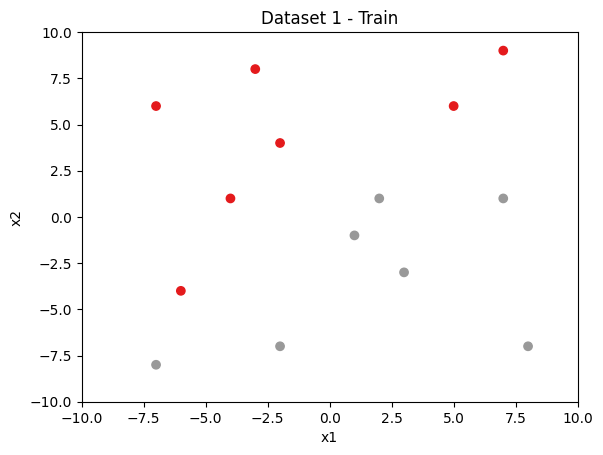

In [24]:
fig, ax = plt.subplots()

data_visualizer.plot(ax, trainset1)

ax.set_title("Dataset 1 - Train")
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)

plt.show()

## Prepare Model

In [25]:
knn_model1 = KnnModel(
    n_classes=2,
    k=1,
    distance_fn=manhattan_distance,
    voting_fn=majority_vote,
)

## Train Model

In [26]:
train_knn(knn_model1, trainset1)

## Analyze Results

In [27]:
x, y = testset1[0]
print(x, y)

scores = knn_model1(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

[ 4.28571429 -9.59183673] 1
[0 1]
1


In [28]:
analyzer = AccuracyAnalyzer()
acc = analyzer.test(knn_model1, testset1)
print(f"{acc * 100:.3f}%")

88.280%


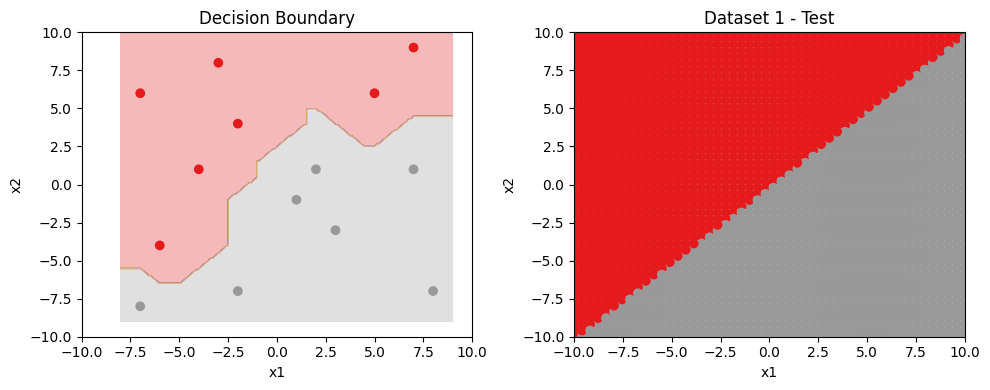

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset1, knn_model1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset1)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 1 - Test")

plt.tight_layout()
plt.show()

# Task 1

Create three new `KnnModel` instances with the following changes (progressive) and explain how the decision boundaries change in each case:

1. Use Euclidean distance.
2. Increase the value of `k` to `3`.
3. Use inverse distance voting (with `EPS` to avoid division by zero).

Then train KNN models on `train1-noisy.csv` and explain the effects of:

1. Different values of `k` (`1` vs. `3`).
2. Different voting strategies (majority vote vs. inverse distance voting).

Your report should compare how these choices affect boundary smoothness, sensitivity to local noise, and prediction stability.

[ 4.28571429 -9.59183673] 1
[0 1]
1
89.040%


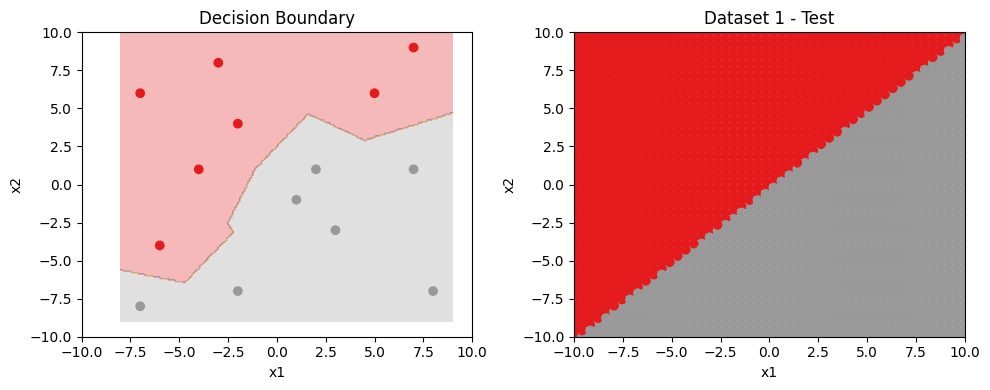

In [30]:
# euclidean distance
knn_model1 = KnnModel(
    n_classes=2,
    k=1,
    distance_fn=euclidean_distance,
    voting_fn=majority_vote,
)

train_knn(knn_model1, trainset1)

x, y = testset1[0]
print(x, y)

scores = knn_model1(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

analyzer = AccuracyAnalyzer()
acc = analyzer.test(knn_model1, testset1)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset1, knn_model1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset1)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 1 - Test")

plt.tight_layout()
plt.show()

[ 4.28571429 -9.59183673] 1
[0 3]
1
86.200%


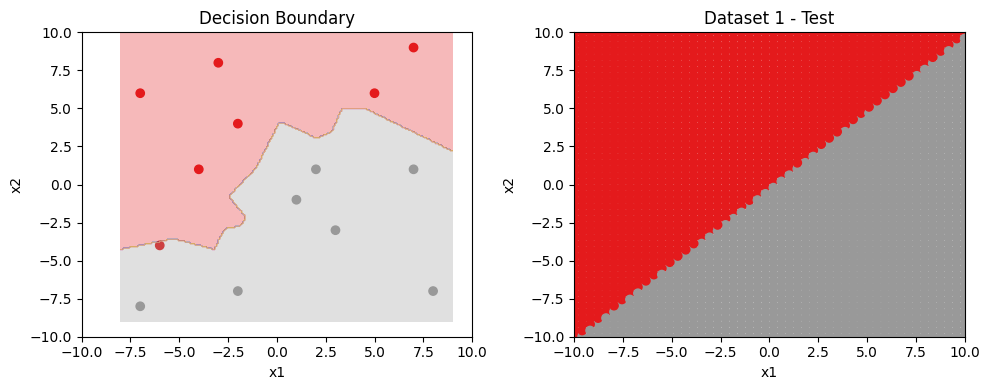

In [31]:
# k=3
knn_model1 = KnnModel(
    n_classes=2,
    k=3,
    distance_fn=euclidean_distance,
    voting_fn=majority_vote,
)

train_knn(knn_model1, trainset1)

x, y = testset1[0]
print(x, y)

scores = knn_model1(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

analyzer = AccuracyAnalyzer()
acc = analyzer.test(knn_model1, testset1)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset1, knn_model1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset1)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 1 - Test")

plt.tight_layout()
plt.show()

[ 4.28571429 -9.59183673] 1
[0.         0.51676533]
1
88.080%


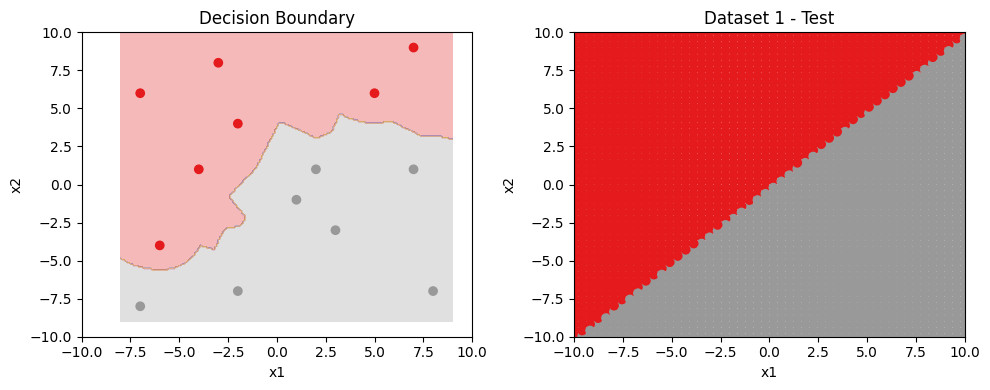

In [32]:
# inverse voting function
knn_model1 = KnnModel(
    n_classes=2,
    k=3,
    distance_fn=euclidean_distance,
    voting_fn=inverse_vote,
)

train_knn(knn_model1, trainset1)

x, y = testset1[0]
print(x, y)

scores = knn_model1(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

analyzer = AccuracyAnalyzer()
acc = analyzer.test(knn_model1, testset1)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset1, knn_model1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset1)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 1 - Test")

plt.tight_layout()
plt.show()

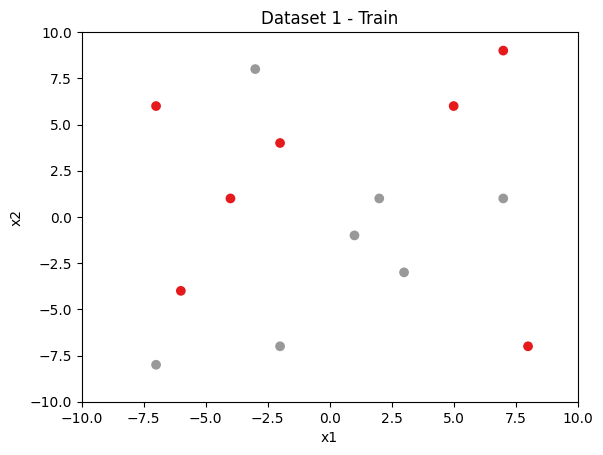

In [33]:
trainset1 = CsvDataset("/content/datasets/train1-noisy.csv")
testset1 = CsvDataset("/content/datasets/test1.csv")

fig, ax = plt.subplots()

data_visualizer.plot(ax, trainset1)

ax.set_title("Dataset 1 - Train")
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)

plt.show()

[ 4.28571429 -9.59183673] 1
[1 0]
0
72.280%


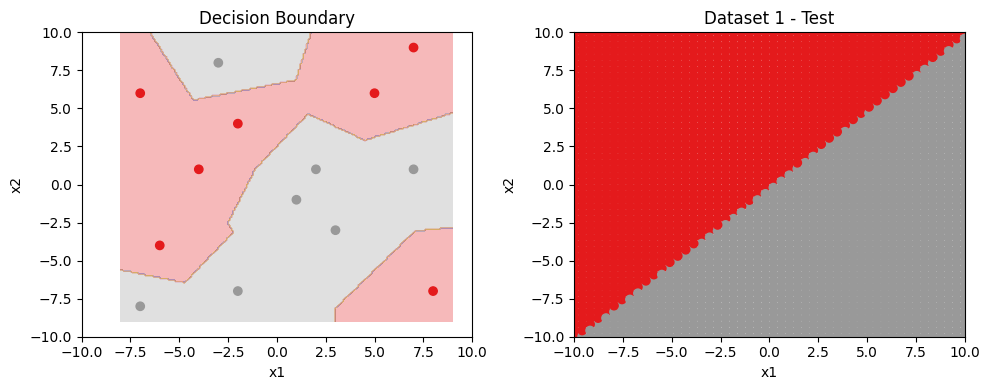

In [34]:
# euclidean distance
knn_model1 = KnnModel(
    n_classes=2,
    k=1,
    distance_fn=euclidean_distance,
    voting_fn=majority_vote,
)

train_knn(knn_model1, trainset1)

x, y = testset1[0]
print(x, y)

scores = knn_model1(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

analyzer = AccuracyAnalyzer()
acc = analyzer.test(knn_model1, testset1)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset1, knn_model1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset1)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 1 - Test")

plt.tight_layout()
plt.show()

[ 4.28571429 -9.59183673] 1
[1 2]
1
85.640%


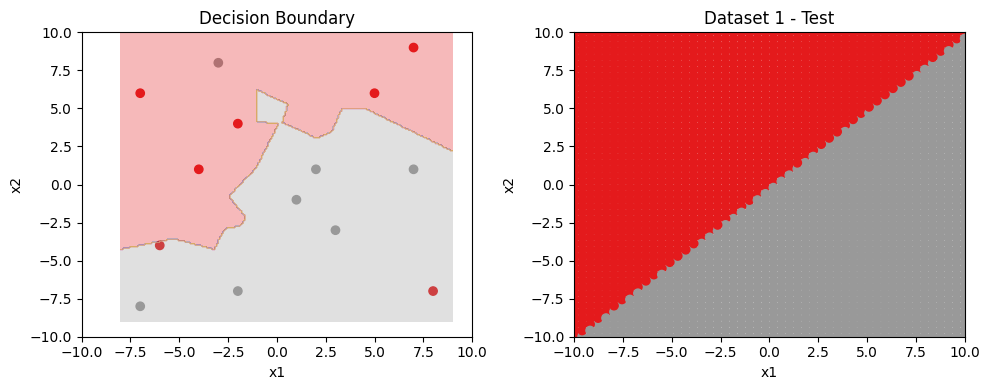

In [35]:
# k=3
knn_model1 = KnnModel(
    n_classes=2,
    k=3,
    distance_fn=euclidean_distance,
    voting_fn=majority_vote,
)

train_knn(knn_model1, trainset1)

x, y = testset1[0]
print(x, y)

scores = knn_model1(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

analyzer = AccuracyAnalyzer()
acc = analyzer.test(knn_model1, testset1)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset1, knn_model1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset1)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 1 - Test")

plt.tight_layout()
plt.show()

[ 4.28571429 -9.59183673] 1
[0.22079017 0.29597516]
1
77.840%


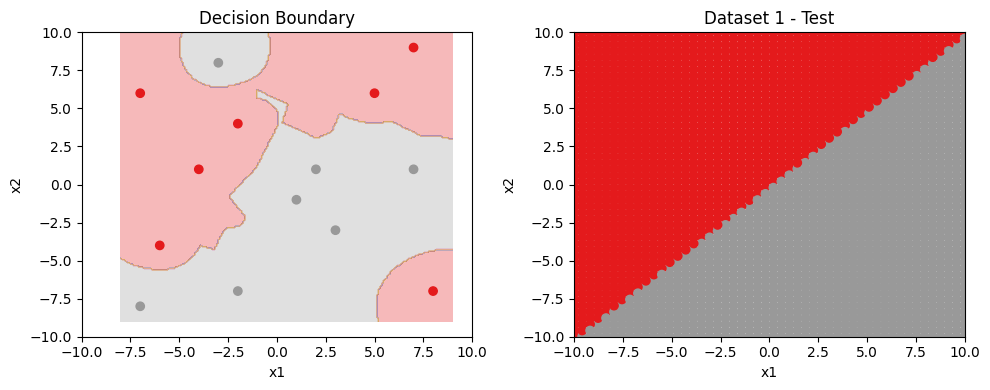

In [36]:
# inverse voting function
knn_model1 = KnnModel(
    n_classes=2,
    k=3,
    distance_fn=euclidean_distance,
    voting_fn=inverse_vote,
)

train_knn(knn_model1, trainset1)

x, y = testset1[0]
print(x, y)

scores = knn_model1(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

analyzer = AccuracyAnalyzer()
acc = analyzer.test(knn_model1, testset1)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset1, knn_model1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset1)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 1 - Test")

plt.tight_layout()
plt.show()

# Task 1 Report

 Switching to Euclidean distance and increasing k smooths the decision boundary and reduces sensitivity to noise. Inverse distance voting gives more influence to closer neighbors, making the boundary more locally accurate while remaining more stable than k=1.

# Linear Classifier

## `LinearClassifier`
`LinearClassifier` is a subclass of `Model` that evaluates class scores using a learned weight matrix and bias vector, producing one score per class from a linear transformation of the input.

In [37]:
class LinearClassifier(Model):
    def __init__(self, n_features, n_classes):
        super().__init__(n_classes)
        self.n_features = n_features
        self.w = np.random.randn(n_classes, n_features)
        self.b = np.random.randn(n_classes)

    def evaluate(self, x):
        return self.w @ x + self.b

## Training Function

### `run_gradient_descent_linear_classifier`
`run_gradient_descent_linear_classifier` trains a `LinearClassifier` using the gradient descent algorithm.

In [38]:
def run_gradient_descent_linear_classifier(model, trainset, num_epochs, loss_calculator, alpha):
    for epoch in range(num_epochs):
        dw = np.zeros_like(model.w)
        db = np.zeros_like(model.b)
        epoch_loss = 0.0

        for x, y in trainset:
            scores = model(x)
            sample_loss, dscore = loss_calculator(scores, y)

            epoch_loss += sample_loss
            dw += np.outer(dscore, x)
            db += dscore

        n = len(trainset)
        dw /= n
        db /= n
        epoch_loss /= n

        model.w -= alpha * dw
        model.b -= alpha * db

## Loss Calculators

### `LossCalculator`
`LossCalculator` is the abstract base class for loss calculators. Each subclass implements a loss function that returns the loss value and the gradient of that loss with respect to the class scores.

### `MulticlassSvmLoss`
`MulticlassSvmLoss` computes the multiclass hinge loss and the gradient of that loss with respect to the class scores.

In [39]:
class LossCalculator:
    def __call__(self, scores, y):
        raise NotImplementedError

In [40]:
class MulticlassSvmLoss(LossCalculator):
    def __init__(self, margin=1.0):
        self.margin = margin

    def __call__(self, scores, y):
        n_classes = len(scores)
        loss = 0.0
        dscore = np.zeros_like(scores)

        for class_id in range(n_classes):
            if class_id == y:
                continue

            margin_value = scores[class_id] - scores[y] + self.margin

            if margin_value > 0:
                loss += margin_value
                dscore[class_id] += 1
                dscore[y] -= 1

        return loss, dscore

# Example 2

## Load Data

In [95]:
trainset2 = CsvDataset("/content/datasets/train2.csv")
testset2 = CsvDataset("/content/datasets/test2.csv")

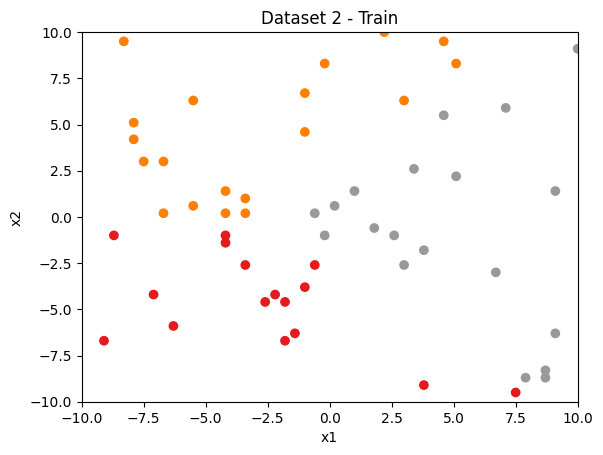

In [42]:
fig, ax = plt.subplots()

data_visualizer.plot(ax, trainset2)

ax.set_title("Dataset 2 - Train")
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)

plt.show()

## Prepare Model

In [96]:
linear_classifier1 = LinearClassifier(
    n_features=2,
    n_classes=3,
)

## Train Model

In [44]:
run_gradient_descent_linear_classifier(
    model=linear_classifier1,
    trainset=trainset2,
    num_epochs=1000,
    loss_calculator=MulticlassSvmLoss(),
    alpha=0.01,
)

## Analyze Results

In [45]:
x, y = testset2[0]
print(x, y)

scores = linear_classifier1(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

[9.18367347 1.42857143] 2
[-2.0643603  -2.53967111  6.82107023]
2


In [46]:
analyzer = AccuracyAnalyzer()
acc = analyzer.test(linear_classifier1, testset2)
print(f"{acc * 100:.3f}%")

98.320%


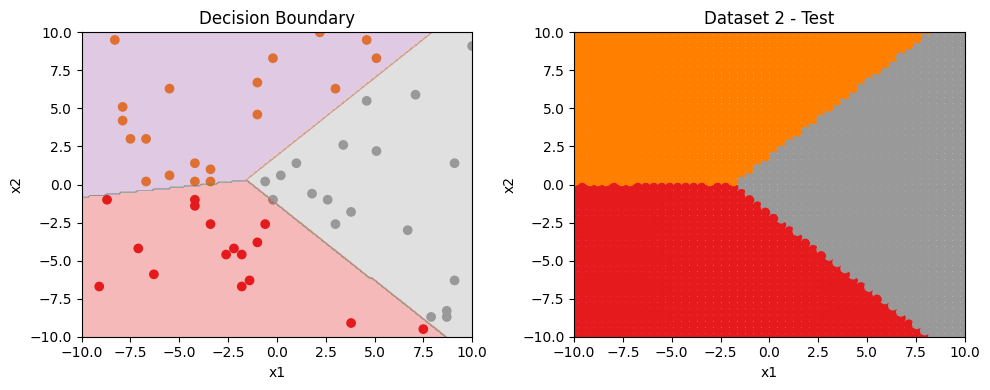

In [47]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset2, linear_classifier1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset2)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 2 - Test")

plt.tight_layout()
plt.show()

# Task 2

Implement a new `LossCalculator` named `CrossEntropyLoss` for the non-tensor linear classifier section.

Your work should include:

1. The `CrossEntropyLoss` class definition.
2. Training a new `LinearClassifier` with that loss on `train2.csv`.
3. Evaluating the trained model on `test2.csv`.
4. Comparing its performance and decision boundary with a `KnnModel` trained on the same dataset.

Your report should explain which model performs better, how their boundaries differ, and why the dataset structure may favor one model over the other.

In [97]:
class CrossEntropyLoss(LossCalculator):
    def __call__(self, scores, y):
        shifted = scores - np.max(scores)
        exp_scores = np.exp(shifted)
        probs = exp_scores / np.sum(exp_scores)

        loss = -np.log(probs[y])

        dscore = probs.copy()
        dscore[y] -= 1

        return loss, dscore

In [98]:
linear_classifier2 = LinearClassifier(
    n_features=2,
    n_classes=3,
)

run_gradient_descent_linear_classifier(
    model=linear_classifier2,
    trainset=trainset2,
    num_epochs=1000,
    loss_calculator=CrossEntropyLoss(),
    alpha=0.01,
)

[9.18367347 1.42857143] 2
[ 1.26018424  2.67941539 14.69014533]
2
98.680%


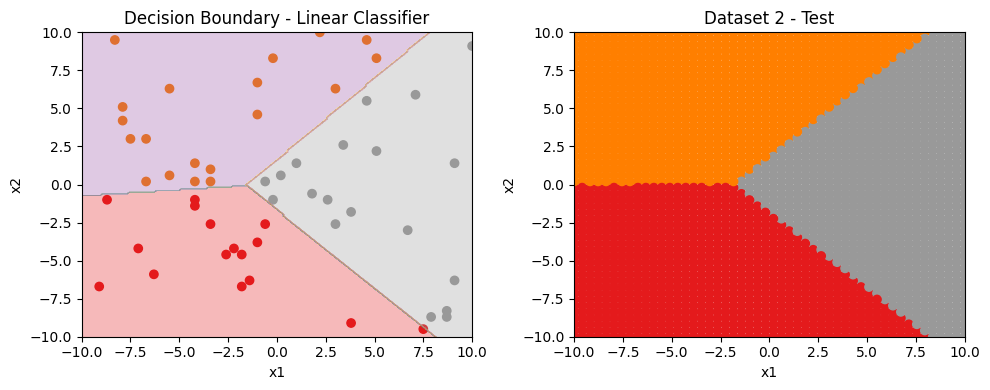

In [99]:
x, y = testset2[0]
print(x, y)

scores = linear_classifier2(x)
print(scores)

y_hat = np.argmax(scores)
print(y_hat)

analyzer = AccuracyAnalyzer()
acc = analyzer.test(linear_classifier2, testset2)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset2, linear_classifier2)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary - Linear Classifier")

data_visualizer.plot(ax2, testset2)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 2 - Test")

plt.tight_layout()
plt.show()

94.840%


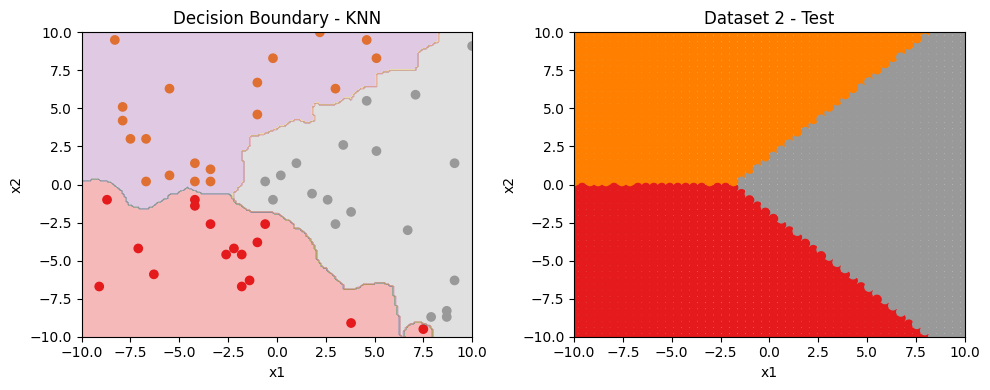

In [51]:
knn_model5 = KnnModel(
    n_classes=3,
    k=3,
    distance_fn=euclidean_distance,
    voting_fn=inverse_vote,
)
train_knn(knn_model5, trainset2)
analyzer = AccuracyAnalyzer()
acc = analyzer.test(knn_model5, testset2)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

model_visualizer.plot(ax1, trainset2, knn_model5)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary - KNN")

data_visualizer.plot(ax2, testset2)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 2 - Test")

plt.tight_layout()
plt.show()

# Task 2 Report


The linear classifier performed better than KNN here since the data is approximately linearly separable, giving it cleaner, straighter boundaries compared to KNN's irregular ones.

# Tensor

## `Tensor`
`Tensor` is an object that stores gradients with data, and the computation graph required for automatic differentiation.

In [52]:
class Tensor:
    def __init__(self, data, requires_grad=False):
        self.data = np.array(data, dtype=float)
        self.requires_grad = requires_grad
        self.grad = None
        self._backward = lambda: None
        self._prev = set()

    def backward(self):
        nodes = []
        visited = set()

        def dfs(node):
            if node in visited: return
            visited.add(node)

            for prev in node._prev: dfs(prev)
            nodes.append(node)

        dfs(self)

        self.grad = np.ones_like(self.data)

        for node in reversed(nodes):
            node._backward()

    def zero_grad(self):
        self.grad = None

    def __repr__(self):
        return f"Tensor(data={self.data}, grad={self.grad})"

### Utility Functions

In [53]:
def ensure_tensor(x):
    if isinstance(x, Tensor):
        return x

    return Tensor(x)

def unbroadcast(grad, shape):
    while len(grad.shape) > len(shape):
        grad = grad.sum(axis=0)

    for axis, size in enumerate(shape):
        if size == 1:
            grad = grad.sum(axis=axis, keepdims=True)

    return grad

## Tensor Operations

### Addition

In [54]:
def tensor_add(a, b):
    a = ensure_tensor(a)
    b = ensure_tensor(b)

    out = Tensor(a.data + b.data, requires_grad=a.requires_grad or b.requires_grad)

    def _backward():
        if a.requires_grad:
            if a.grad is None:
                a.grad = np.zeros_like(a.data)

            a.grad += unbroadcast(out.grad, a.data.shape)

        if b.requires_grad:
            if b.grad is None:
                b.grad = np.zeros_like(b.data)

            b.grad += unbroadcast(out.grad, b.data.shape)

    out._backward = _backward
    out._prev = {a, b}

    return out

In [55]:
Tensor.__add__ = lambda self, other: tensor_add(self, other)
Tensor.__radd__ = lambda self, other: tensor_add(other, self)

### Element-wise Multiplication

In [56]:
def tensor_multiply(a, b):
    a = ensure_tensor(a)
    b = ensure_tensor(b)

    out = Tensor(a.data * b.data, requires_grad=a.requires_grad or b.requires_grad)

    def _backward():
        if a.requires_grad:
            if a.grad is None:
                a.grad = np.zeros_like(a.data)

            grad_a = out.grad * b.data
            a.grad += unbroadcast(grad_a, a.data.shape)

        if b.requires_grad:
            if b.grad is None:
                b.grad = np.zeros_like(b.data)

            grad_b = out.grad * a.data
            b.grad += unbroadcast(grad_b, b.data.shape)

    out._backward = _backward
    out._prev = {a, b}

    return out

In [57]:
Tensor.__mul__ = lambda self, other: tensor_multiply(self, other)
Tensor.__rmul__ = lambda self, other: tensor_multiply(other, self)

### Matrix Multiplication

In [58]:
def tensor_matmul(a, b):
    a = ensure_tensor(a)
    b = ensure_tensor(b)

    out = Tensor(a.data @ b.data, requires_grad=a.requires_grad or b.requires_grad)

    def _backward():
        if a.requires_grad:
            if a.grad is None:
                a.grad = np.zeros_like(a.data)

            a.grad += np.outer(out.grad, b.data)

        if b.requires_grad:
            if b.grad is None:
                b.grad = np.zeros_like(b.data)

            b.grad += a.data.T @ out.grad

    out._backward = _backward
    out._prev = {a, b}

    return out

In [59]:
Tensor.__matmul__ = lambda self, other: tensor_matmul(self, other)

### Negation

In [60]:
def tensor_neg(a):
    a = ensure_tensor(a)

    out = Tensor(-a.data, requires_grad=a.requires_grad)

    def _backward():
        if a.requires_grad:
            if a.grad is None:
                a.grad = np.zeros_like(a.data)

            a.grad -= out.grad

    out._backward = _backward
    out._prev = {a}

    return out

In [61]:
Tensor.__neg__ = lambda self: tensor_neg(self)

### Subtraction

In [62]:
def tensor_sub(a, b):
    a = ensure_tensor(a)
    return a + tensor_neg(b)

In [63]:
Tensor.__sub__ = lambda self, other: tensor_sub(self, other)
Tensor.__rsub__ = lambda self, other: tensor_sub(other, self)

### Division

In [64]:
def tensor_div(a, b):
    a = ensure_tensor(a)
    b = ensure_tensor(b)

    out = Tensor(a.data / b.data, requires_grad=a.requires_grad or b.requires_grad)

    def _backward():
        if a.requires_grad:
            if a.grad is None:
                a.grad = np.zeros_like(a.data)

            grad_a = out.grad / b.data
            a.grad += unbroadcast(grad_a, a.data.shape)

        if b.requires_grad:
            if b.grad is None:
                b.grad = np.zeros_like(b.data)

            grad_b = -out.grad * a.data / (b.data ** 2)
            b.grad += unbroadcast(grad_b, b.data.shape)

    out._backward = _backward
    out._prev = {a, b}

    return out

In [65]:
Tensor.__truediv__ = lambda self, other: tensor_div(self, other)
Tensor.__rtruediv__ = lambda self, other: tensor_div(other, self)

### Indexing

In [66]:
def tensor_getitem(x, idx):
    x = ensure_tensor(x)

    out = Tensor(x.data[idx], requires_grad=x.requires_grad)

    def _backward():
        if x.requires_grad:
            if x.grad is None:
                x.grad = np.zeros_like(x.data)

            x.grad[idx] += out.grad

    out._backward = _backward
    out._prev = {x}

    return out

In [67]:
Tensor.__getitem__ = tensor_getitem

### Sum

In [68]:
def tensor_sum(x):
    x = ensure_tensor(x)

    out = Tensor(np.sum(x.data), requires_grad=x.requires_grad)

    def _backward():
        if x.requires_grad:
            if x.grad is None:
                x.grad = np.zeros_like(x.data)

            x.grad += out.grad * np.ones_like(x.data)

    out._backward = _backward
    out._prev = {x}

    return out

### Exp

In [69]:
def tensor_exp(a):
    a = ensure_tensor(a)

    out = Tensor(np.exp(a.data), requires_grad=a.requires_grad)

    def _backward():
        if a.requires_grad:
            if a.grad is None:
                a.grad = np.zeros_like(a.data)

            a.grad += out.grad * out.data

    out._backward = _backward
    out._prev = {a}

    return out

### Log

In [70]:
def tensor_log(a):
    a = ensure_tensor(a)

    out = Tensor(np.log(a.data), requires_grad=a.requires_grad)

    def _backward():
        if a.requires_grad:
            if a.grad is None:
                a.grad = np.zeros_like(a.data)

            a.grad += out.grad / a.data

    out._backward = _backward
    out._prev = {a}

    return out

### Max

In [71]:
def tensor_max(a, b):
    a = ensure_tensor(a)
    b = ensure_tensor(b)

    out = Tensor(np.maximum(a.data, b.data), requires_grad=a.requires_grad or b.requires_grad)

    def _backward():
        greater_a = a.data > b.data
        greater_b = b.data > a.data
        equal_mask = a.data == b.data

        if a.requires_grad:
            if a.grad is None:
                a.grad = np.zeros_like(a.data)

            grad_a = out.grad * (greater_a + 0.5 * equal_mask)
            a.grad += unbroadcast(grad_a, a.data.shape)

        if b.requires_grad:
            if b.grad is None:
                b.grad = np.zeros_like(b.data)

            grad_b = out.grad * (greater_b + 0.5 * equal_mask)
            b.grad += unbroadcast(grad_b, b.data.shape)

    out._backward = _backward
    out._prev = {a, b}

    return out

# Analyzer Classes for Tensors

## `TensorModelPerformanceAnalyzer`
`TensorModelPerformanceAnalyzer` evaluates a tensor-based model on a dataset by collecting predictions and then delegating metric computation to a subclass.

In [72]:
class TensorModelPerformanceAnalyzer:
    def test(self, model, testset):
        y_true = []
        y_pred = []

        for x, y in testset:
            scores = model(x).data
            y_hat = np.argmax(scores)

            y_true.append(y)
            y_pred.append(y_hat)

        return self.compute(np.array(y_true), np.array(y_pred))

    def compute(self, y_true, y_pred):
        raise NotImplementedError(f"{self.__class__.__name__}.compute() must be implemented")

In [73]:
class TensorAccuracyAnalyzer(TensorModelPerformanceAnalyzer):
    def compute(self, y_true, y_pred):
        return np.mean(y_true == y_pred)

In [74]:
class TensorF1Analyzer(TensorModelPerformanceAnalyzer):
    def __init__(self, n_classes, positive_class_ids=None):
        self.n_classes = n_classes
        self.positive_class_ids = (
            list(range(n_classes)) if positive_class_ids is None else positive_class_ids
        )

    def compute(self, y_true, y_pred):
        f1_scores = []

        for class_id in self.positive_class_ids:
            tp = np.sum((y_pred == class_id) & (y_true == class_id))
            fp = np.sum((y_pred == class_id) & (y_true != class_id))
            fn = np.sum((y_pred != class_id) & (y_true == class_id))

            precision = tp / (tp + fp + EPS)
            recall = tp / (tp + fn + EPS)
            f1 = 2 * precision * recall / (precision + recall + EPS)

            f1_scores.append(f1)

        return np.mean(f1_scores)

# Visualizer Classes for Tensors

## `TensorModelVisualizer2D`
`TensorModelVisualizer2D` plots tensor-model decision regions over a two-dimensional grid and overlays the dataset points.

In [75]:
class TensorModelVisualizer2D:
    def __init__(self, resolution=200, cmap="Set1", alpha=0.3):
        self.resolution = resolution
        self.cmap = cmap
        self.alpha = alpha

    def plot(self, ax, dataset, model):
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")

        X = np.array([x for x, _ in dataset])
        y = np.array([y for _, y in dataset])

        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=self.cmap)

        x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

        xx, yy = np.meshgrid(
            np.linspace(x1_min, x1_max, self.resolution),
            np.linspace(x2_min, x2_max, self.resolution),
        )

        grid = np.c_[xx.ravel(), yy.ravel()]
        scores = np.array([model(x).data for x in grid])
        Z = np.argmax(scores, axis=1).reshape(xx.shape)

        ax.contourf(xx, yy, Z, alpha=self.alpha, cmap=self.cmap)

        return ax

In [76]:
tensor_model_visualizer = TensorModelVisualizer2D()

# Tensor-Based Linear Classifier

## `LinearClassifierTensor`
`LinearClassifierTensor` is the tensor-based version of `LinearClassifier`, storing trainable parameters as `Tensor` objects so gradients can be computed automatically.

In [77]:
class LinearClassifierTensor(LinearClassifier):
    def __init__(self, n_features, n_classes):
        super().__init__(n_features, n_classes)

        self.w = Tensor(np.random.randn(n_classes, n_features), requires_grad=True)
        self.b = Tensor(np.random.randn(n_classes), requires_grad=True)

## Training Function

### `run_gradient_descent_linear_classifier_tensor`
`run_gradient_descent_linear_classifier_tensor` trains a tensor-based linear classifier using gradient descent.

In [78]:
def run_gradient_descent_linear_classifier_tensor(model, trainset, num_epochs, loss_calculator, alpha):
    for epoch in range(num_epochs):
        model.w.zero_grad()
        model.b.zero_grad()
        epoch_loss = Tensor(0.0)

        for x, y in trainset:
            scores = model(x)
            sample_loss = loss_calculator(scores, y)
            epoch_loss = epoch_loss + sample_loss

        n = len(trainset)
        epoch_loss = epoch_loss / n
        epoch_loss.backward()

        model.w.data -= alpha * model.w.grad
        model.b.data -= alpha * model.b.grad

## Loss Calculators

### `TensorLossCalculator`
`TensorLossCalculator` is the abstract base class for loss functions used by tensor-based models.

### `TensorCrossEntropyLoss`
`TensorCrossEntropyLoss` computes cross-entropy loss using tensor operations so gradients flow through the computational graph.

In [79]:
class TensorLossCalculator:
    def __call__(self, scores, y):
        raise NotImplementedError

In [80]:
class TensorCrossEntropyLoss(TensorLossCalculator):
    def __call__(self, scores, y):
        shifted_scores = scores - np.max(scores.data)
        probabilities = self.softmax(shifted_scores)
        return -tensor_log(probabilities[y] + EPS)

    @staticmethod
    def softmax(scores):
        exp_scores = tensor_exp(scores)
        return exp_scores / tensor_sum(exp_scores)

# Example 3

## Load Data

In [81]:
trainset2 = CsvDataset("/content/datasets/train2.csv")
testset2 = CsvDataset("/content/datasets/test2.csv")

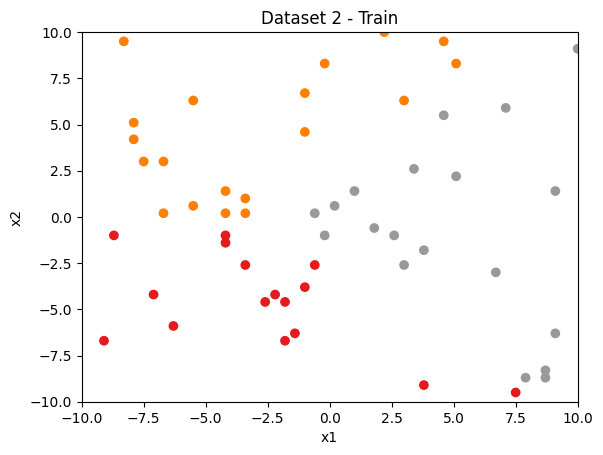

In [82]:
fig, ax = plt.subplots()

data_visualizer.plot(ax, trainset2)

ax.set_title("Dataset 2 - Train")
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)

plt.show()

## Prepare Model

In [83]:
linear_classifier_tensor1 = LinearClassifierTensor(
    n_features=2,
    n_classes=3,
)

## Train Model

In [84]:
run_gradient_descent_linear_classifier_tensor(
    model=linear_classifier_tensor1,
    trainset=trainset2,
    num_epochs=1000,
    loss_calculator=TensorCrossEntropyLoss(),
    alpha=0.01,
)

## Analyze Results

In [85]:
x, y = testset2[0]
print(x, y)

scores = linear_classifier_tensor1(x)
print(scores)

y_hat = np.argmax(scores.data)
print(y_hat)

[9.18367347 1.42857143] 2
Tensor(data=[-23.34214133 -18.66238348  -7.51773592], grad=None)
2


In [86]:
analyzer = TensorAccuracyAnalyzer()
acc = analyzer.test(linear_classifier_tensor1, testset2)
print(f"{acc * 100:.3f}%")

98.440%


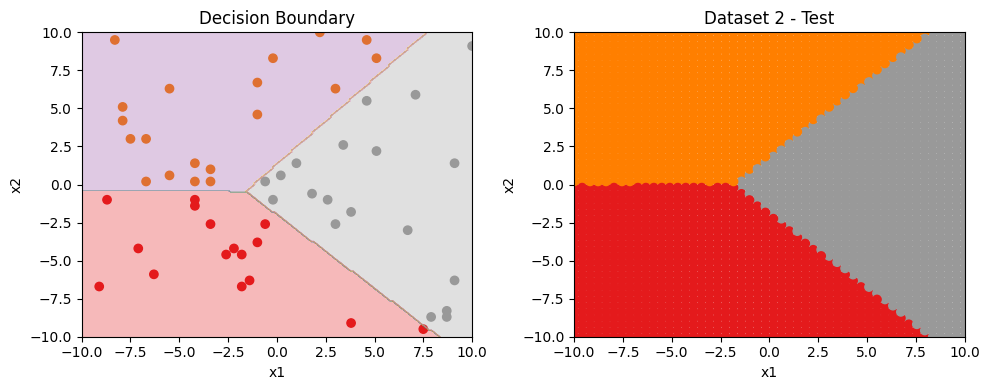

In [87]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

tensor_model_visualizer.plot(ax1, trainset2, linear_classifier_tensor1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset2)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 2 - Test")

plt.tight_layout()
plt.show()

# Task 3

Train a `LinearClassifierTensor` on `train3.csv` and evaluate it on `test3.csv`.

Your work should include:

1. Loading the dataset.
2. Creating and training the model.
3. Calculating the accuracy on the testset.
4. Visualizing the resulting decision boundary.

Your report should explain how well a linear decision boundary fits Dataset 3 and what the result suggests about the dataset geometry.

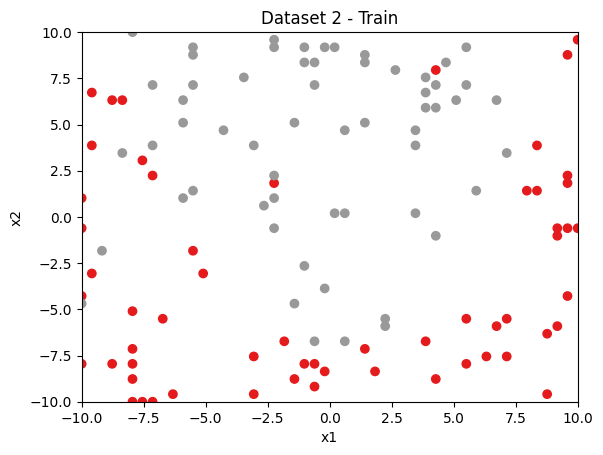

[9.18367347 1.42857143] 0
Tensor(data=[-0.42708561 -0.47391302 -2.82517001], grad=None)
0
74.160%


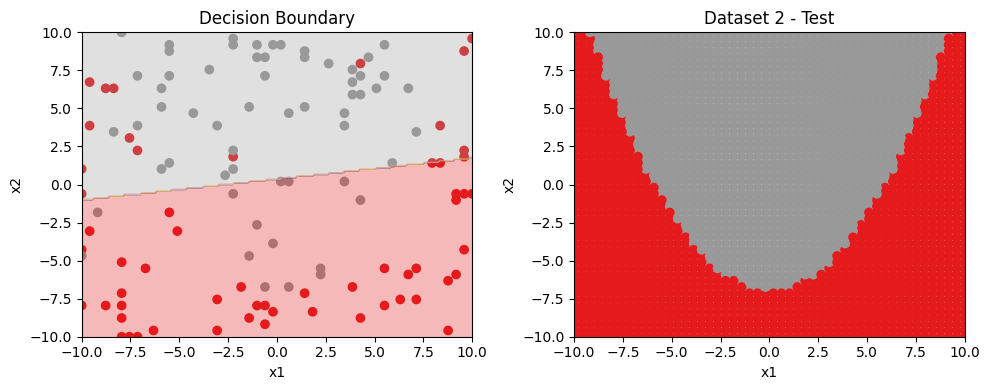

In [88]:
trainset2 = CsvDataset("/content/datasets/train3.csv")
testset2 = CsvDataset("/content/datasets/test3.csv")

fig, ax = plt.subplots()

data_visualizer.plot(ax, trainset2)

ax.set_title("Dataset 2 - Train")
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)

plt.show()

linear_classifier_tensor1 = LinearClassifierTensor(
    n_features=2,
    n_classes=3,
)

run_gradient_descent_linear_classifier_tensor(
    model=linear_classifier_tensor1,
    trainset=trainset2,
    num_epochs=1000,
    loss_calculator=TensorCrossEntropyLoss(),
    alpha=0.01,
)

x, y = testset2[0]
print(x, y)

scores = linear_classifier_tensor1(x)
print(scores)

y_hat = np.argmax(scores.data)
print(y_hat)

analyzer = TensorAccuracyAnalyzer()
acc = analyzer.test(linear_classifier_tensor1, testset2)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

tensor_model_visualizer.plot(ax1, trainset2, linear_classifier_tensor1)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary")

data_visualizer.plot(ax2, testset2)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 2 - Test")

plt.tight_layout()
plt.show()

# Task 3 Report

The provided dataset is not linearly separable. That's why the linear classifier tensor had poor results. A non linear decision boundary would better suit this data as we can see from the data visualization as well.

# Neural Networks

## `NeuralNetwork`
`NeuralNetwork` builds a feedforward neural network with hidden layers, using tensor operations.

In [89]:
class NeuralNetwork(Model):
    def __init__(self, n_features, n_classes, hidden_layer_sizes):
        super().__init__(n_classes)

        layer_sizes = [n_features] + hidden_layer_sizes + [n_classes]
        self.weights = []
        self.biases = []

        for in_size, out_size in zip(layer_sizes[:-1], layer_sizes[1:]):
            self.weights.append(Tensor(np.random.randn(out_size, in_size), requires_grad=True))
            self.biases.append(Tensor(np.random.randn(out_size), requires_grad=True))

    def evaluate(self, x):
        x = ensure_tensor(x)
        num_layers = len(self.weights)

        for layer_idx in range(num_layers):
            x = self.weights[layer_idx] @ x + self.biases[layer_idx]

            if layer_idx != num_layers - 1:
                x = tensor_max(x, 0.0)

        return x

    def parameters(self):
        return self.weights + self.biases

## Training Function

### `run_gradient_descent_neural_network`
`run_gradient_descent_neural_network` trains a neural network using gradient descent.

In [90]:
def run_gradient_descent_neural_network(model, trainset, num_epochs, loss_calculator, alpha):
    for epoch in range(num_epochs):
        for param in model.parameters():
            param.zero_grad()
        epoch_loss = Tensor(0.0)

        for x, y in trainset:
            scores = model(x)
            sample_loss = loss_calculator(scores, y)
            epoch_loss = epoch_loss + sample_loss

        n = len(trainset)
        epoch_loss = epoch_loss / n
        epoch_loss.backward()

        for param in model.parameters():
            param.data -= alpha * param.grad

# Task 4

Train a `NeuralNetwork` on `train3.csv` and evaluate it on `test3.csv`.

Your work should include:

1. Choosing a hidden-layer configuration.
2. Training the model with `TensorCrossEntropyLoss`.
3. Visualizing the decision boundary.
4. Comparing the neural network with your linear classifier from Task 3.

Your report should explain whether the neural network handles Dataset 3 better than a linear model and why.

**Bonus**: Write a new training function that adds L2 regularization to the neural network objective and discuss how regularization changes the result.

91.600%


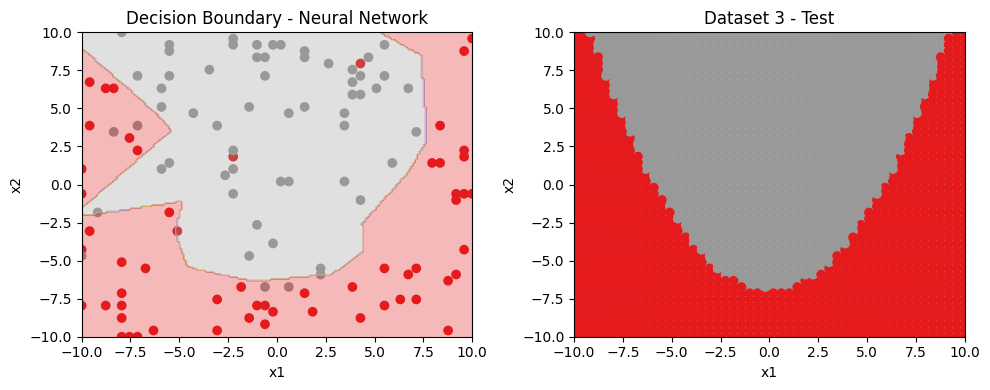

In [100]:
trainset3 = CsvDataset("/content/datasets/train3.csv")
testset3 = CsvDataset("/content/datasets/test3.csv")

nn_model = NeuralNetwork(
    n_features=2,
    n_classes=2,
    hidden_layer_sizes=[8, 8],
)

run_gradient_descent_neural_network(
    model=nn_model,
    trainset=trainset3,
    num_epochs=1000,
    loss_calculator=TensorCrossEntropyLoss(),
    alpha=0.01,
)

analyzer = TensorAccuracyAnalyzer()
acc = analyzer.test(nn_model, testset3)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

tensor_model_visualizer.plot(ax1, trainset3, nn_model)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("Decision Boundary - Neural Network")

data_visualizer.plot(ax2, testset3)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("Dataset 3 - Test")

plt.tight_layout()
plt.show()

# Task 4 Report

The neural network handles dataset 3 much better than the linear classifier because the data is not linearly separable, and the two hidden layers of 8 neurons each allowed it to learn a curved decision boundary that fits the data's actual shape

# Bonus Task

In [104]:
def run_gradient_descent_neural_network_l2(model, trainset, num_epochs, loss_calculator, alpha, lambda_reg=0.01):
    for epoch in range(num_epochs):
        for param in model.parameters():
            param.zero_grad()
        epoch_loss = Tensor(0.0)

        for x, y in trainset:
            scores = model(x)
            sample_loss = loss_calculator(scores, y)
            epoch_loss = epoch_loss + sample_loss

        n = len(trainset)
        epoch_loss = epoch_loss / n

        for param in model.weights:
            l2_penalty = tensor_sum(param * param) * (lambda_reg / 2)
            epoch_loss = epoch_loss + l2_penalty

        epoch_loss.backward()

        for param in model.parameters():
            param.data -= alpha * param.grad

87.600%


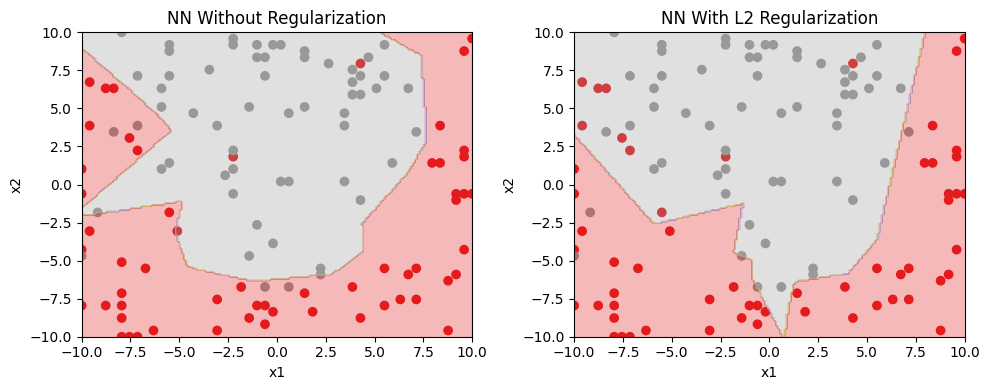

In [106]:
nn_model_l2 = NeuralNetwork(
    n_features=2,
    n_classes=2,
    hidden_layer_sizes=[8, 8],
)

run_gradient_descent_neural_network_l2(
    model=nn_model_l2,
    trainset=trainset3,
    num_epochs=1000,
    loss_calculator=TensorCrossEntropyLoss(),
    alpha=0.01,
    lambda_reg=0.01,
)

analyzer = TensorAccuracyAnalyzer()
acc = analyzer.test(nn_model_l2, testset3)
print(f"{acc * 100:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

tensor_model_visualizer.plot(ax1, trainset3, nn_model)
ax1.set_xlim(-10, 10)
ax1.set_ylim(-10, 10)
ax1.set_title("NN Without Regularization")

tensor_model_visualizer.plot(ax2, trainset3, nn_model_l2)
ax2.set_xlim(-10, 10)
ax2.set_ylim(-10, 10)
ax2.set_title("NN With L2 Regularization")

plt.tight_layout()
plt.show()

L2 regularization penalizes large weights, pushing the model toward simpler, smoother decision boundaries and reducing overfitting. The accuracy dropped a little compared to the unregularized model, but the boundary generalizes better on unseen data.